# Cost per asset: Santa's cards

Run this notebook on your **laptop**. No GPU and no credits needed. It follows the guide, [05-measuring-costs.md](../05-measuring-costs.md), section by section, and draws the same charts.

It reads batch runs that made Santa's animated greeting cards for 20 kids, on three GPUs. It turns the run times into a cost per card, first at **regular** prices, then at **spot** prices. Then it compares the most expensive step with a per-call API for the same model.

You're done when you have:

- the per-step table for one run: each model's load time and the median time per card;
- the cost per card at N = 1, 10, 20 and 200 at regular prices, extrapolated from that one run;
- the cost per card on each GPU;
- what spot prices change;
- a breakeven N for the clip step against a per-call API for the same model, at regular and spot prices.

You don't run anything new: one run is enough, ours or your own lesson 04 run (section 1), and the other GPUs are our runs. Section 7 runs your own lesson 04 run through the same steps.

> ⚠️ **Read this first**
>
> 💸 **Prices here are examples only.** They come from our runs and price checks on the dates shown, and what you pay can differ: prices change, and spot prices can change every 15 minutes. For real prices, see [Compute pricing](https://docs.nebius.com/compute/resources/pricing) and [spot prices](https://docs.nebius.com/signup-billing/spot-prices).
>
> ⚠️ **Remove all running resources after the lesson to prevent bills.** Stop or delete every Endpoint, Job and DevLab you started, even after a failed run, and delete bucket data you no longer need. An Endpoint or DevLab keeps billing while it runs, even when idle.

In [60]:
import json
import statistics
import sys
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt

MODULE = "01-consistent-media-generation-on-serverless-gpus"
candidates = [Path.cwd(), Path.cwd() / "code", Path.cwd() / MODULE / "code"]
found = [p for p in candidates if (p / "common.py").is_file()]
assert found, "Open this notebook from the repository (its code/ folder)"
CODE = found[0].resolve()
RUNS_DIR = CODE.parent / "assets" / "example_runs"
sys.path.insert(0, str(CODE))

import costs  # cost helpers and the guide's charts
from common import calculate_cost
from models import WAN_I2V

## 0. Prices and assumptions

Update this section first. The guide explains these prices in its own "Prices and assumptions" section; the notebook needs them first, because every cost below comes from this one cell. When prices change, update the cell and run the notebook again.

- **Regular:** the on-demand price from [Compute pricing](https://docs.nebius.com/compute/resources/pricing). H100, H200 and RTX PRO 6000 list one price per GPU hour.
- **Spot:** the price for preemptible GPUs, which our example runs used. It can change as often as every 15 minutes and isn't capped: it can rise above the regular price ([Compute pricing](https://docs.nebius.com/compute/resources/pricing)). A [pricing policy](https://docs.nebius.com/signup-billing/pricing-policy) sets a max price. A spot price here is a snapshot: what a run paid can differ. Read it from the [spot-price API](https://docs.nebius.com/signup-billing/spot-prices) (the next cell prints it).
- **API:** one per-call price for the same model as our clip step, Wan 2.2 A14B image-to-video, from fal's model page. We compare the clip step only.

`metrics_batch.json` starts when the worker starts. The time before it, from **Create** until the container runs, is the startup. It isn't in the file, so we type it here: one H100 Job measured it on 2026-11-14.

In [61]:
PRICE_DATE = "2026-11-15"  # when the prices below were read
SPOT_SNAPSHOT = "2026-11-14T15:05Z"  # snapshotTime the spot-price API returned that day

# USD per hour for one GPU and the preset the run used
PRICES = {
    "H100": {
        "file": "h100.json",
        "platform": "gpu-h100-sxm",
        "region": "eu-north1",
        "regular": 4.50,
        "spot": 2.07,
    },
    "H200": {
        "file": "h200.json",
        "platform": "gpu-h200-sxm",
        "region": "eu-north1",
        "regular": 5.40,
        "spot": 2.48,
    },
    # RTX PRO 6000 (gpu-rtx6000-a): our run was in uk-south2
    "RTX PRO 6000": {
        "file": "rtx-pro-6000.json",
        "platform": "gpu-rtx6000-a",
        "region": "uk-south2",
        "regular": 1.80,
        "spot": 1.38,
    },
}

# Per-call API for the clip step: the same model, Wan 2.2 A14B image-to-video
API = {
    "provider": "fal",
    "model": "fal-ai/wan/v2.2-a14b/image-to-video",
    "link": "https://fal.ai/models/fal-ai/wan/v2.2-a14b/image-to-video",
    "resolution": "480p",
    "usd_per_video_s": 0.04,  # 480p; the page lists 0.06 for 580p and 0.08 for 720p
    "frames_per_video_s": 16,  # fal counts video seconds at 16 frames per second
    "checked": "2026-11-15",
}

T_START_S = 157.7  # s, Create -> container running; one H100 Job, 2026-11-14
MAIN_GPU = "H100"  # the run sections 1 to 4.2 use

In [62]:
# Optional: today's spot prices for the platforms above, to update PRICES.
# Cloudflare rejects urllib's default User-Agent (error 1010).
url = "https://api.nebius.cloud/billing/v1alpha1/spot-price"
request = urllib.request.Request(url, headers={"User-Agent": "course-notebook"})
with urllib.request.urlopen(request, timeout=30) as response:
    spot = json.load(response)
platforms = {p["platform"] for p in PRICES.values()}
print("snapshot:", spot["snapshotTime"])
for item in spot["items"]:
    if item["computeInstance"]["platform"] in platforms:
        price = item["price"]
        print(
            f"{item['computeInstance']['platform']:<15}{item['region']:<13}"
            f"{price['value']} {price['currency']} per {price['unitTitle']}, "
            f"since {item['effectiveTime']}"
        )

snapshot: 2026-11-17T22:20:45.404865Z
gpu-h200-sxm   eu-north1    2.18 usd per GPU hour, since 2026-11-17T19:31:00Z
gpu-h100-sxm   eu-north1    1.55 usd per GPU hour, since 2026-11-17T22:21:00Z
gpu-rtx6000-a  eu-south1    1.38 usd per GPU hour, since 2026-11-17T15:36:00Z
gpu-h200-sxm   eu-west1     2.35 usd per GPU hour, since 2026-11-17T22:21:00Z
gpu-rtx6000-a  uk-south2    1.38 usd per GPU hour, since 2026-11-17T09:06:00Z
gpu-h200-sxm   us-central1  2.5 usd per GPU hour, since 2026-11-17T21:31:00Z


## 1. The example runs

`metrics_batch.json` is written by the worker inside the Job. For each step it has the model load time (`load_s`) and the time for each kid (`latency_s`). The startup isn't in the file: section 0 adds it as `T_START_S`.

To put your own lesson 04 run through the same steps, use section 7.

In [63]:
def load_run(gpu: str) -> dict:
    """Read one of our runs from assets/example_runs/."""
    return costs.read_run(RUNS_DIR / PRICES[gpu]["file"])


m = load_run(MAIN_GPU)
steps = m["steps"]
print(f"{m['n']} kids on {m['gpu']}, steps: {', '.join(steps)}")
print(f"worker runtime: {m['runtime_s']:.1f} s, started {m['started_at']}")

20 kids on NVIDIA H100 80GB HBM3, steps: text, illustration, card, clip, greeting, mix
worker runtime: 2726.1 s, started 2026-11-14T17:27:32.246992+00:00


## 2. Where the time goes

Each step loads its model **once** (`load_s`), then makes one asset per kid (`latency_s`). We use the median per kid: the first asset of each model is slower (warm-up), and the median keeps that out of the per-card time.

The card and mix steps run on the CPU, but inside the same GPU VM, so they bill at the GPU price too.

In [64]:
per_card = costs.card_times(steps)  # one card = the sum of its step times
t_gen = statistics.median(per_card)
t_load = costs.model_loads(steps)  # raises if a GPU step has no load time
t_fixed = T_START_S + t_load

costs.print_steps(steps)
print(
    f"\nfixed, once per run: startup {T_START_S:.1f} s + model loads {t_load:.1f} s "
    f"= {t_fixed:.1f} s"
)
print(f"marginal, once per card: median {t_gen:.1f} s")

step         runs on     load s  first s  median s  % of card
text         CPU              -      0.0       0.0       0.0%
illustration GPU           89.9      6.0       0.8       1.0%
card         CPU              -      0.4       0.4       0.5%
clip         GPU         1046.0     77.7      76.7      97.4%
greeting     GPU            7.3      2.2       0.2       0.2%
mix          CPU              -      0.6       0.6       0.7%

fixed, once per run: startup 157.7 s + model loads 1143.2 s = 1300.9 s
marginal, once per card: median 78.7 s


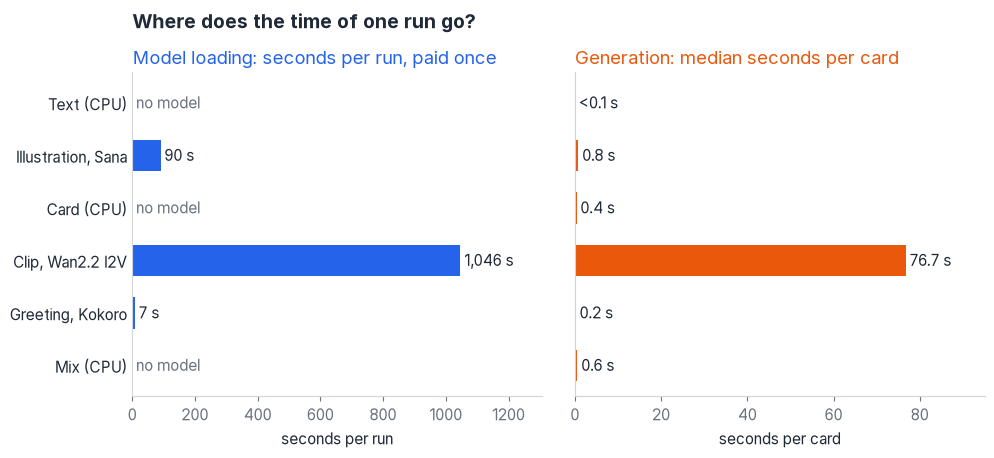

In [65]:
fig = costs.time_chart(steps)
plt.show()

How much of the billed time is the fixed part, for a run of N cards? No price needed yet: these are GPU-seconds.

In [66]:
for n in (1, 10, 20, 200):
    billed = t_fixed + n * t_gen
    print(f"N={n:<4} billed ≈ {billed / 60:6.1f} min, fixed part {100 * t_fixed / billed:5.1f}%")

N=1    billed ≈   23.0 min, fixed part  94.3%
N=10   billed ≈   34.8 min, fixed part  62.3%
N=20   billed ≈   47.9 min, fixed part  45.2%
N=200  billed ≈  284.1 min, fixed part   7.6%


## 3. From time to money

Every cost below is a projection: what a run costs at a given price, from its times. What you actually paid is in **Billing → Usage**.

- Marginal cost per card: `c = rate × t_gen`.
- Fixed cost per run: `F = rate × (t_start + t_load)`.
- Total per card for N cards: `F / N + c`.
- Breakeven against a per-call API at `p` per asset: `N = ceil(F / (p − c))`. If `p ≤ c`, there's no finite breakeven: self-hosting never wins. `calculate_cost` returns `0` for that case, and the notebook prints "never (0)"; the homework uses `0` the same way.

**Assumptions:** the run is one Job, as in `metrics_batch.json`: one startup, billed in full, then the cards one after another.
**Left out:** the container disk, the first-asset warm-up, failed or retried runs, engineering and ops time, bucket storage and egress, and quality differences against an API. Each one makes self-hosting look cheaper than it is.

`c` is the *marginal* cost, never "the cost per card": with N = 1, the fixed part is most of the bill. `calculate_cost()` in `common.py` does this arithmetic for every section below. Here it is for 20 cards:

In [67]:
rate = PRICES[MAIN_GPU]["regular"]
cost = calculate_cost(T_START_S, t_load, per_card, rate, counts=(20,))
F, c = cost["fixed_run_usd"], cost["marginal_compute_usd"]
print(f"{MAIN_GPU}, regular price {rate:.2f} USD/h ({PRICE_DATE}): F = ${F:.2f}, c = ${c:.4f}")
print(f"N=20: ${F:.2f} / 20 + ${c:.4f} = ${F / 20 + c:.4f} per card")

H100, regular price 4.50 USD/h (2026-11-15): F = $1.63, c = $0.0984
N=20: $1.63 / 20 + $0.0984 = $0.1797 per card


## 4. The analysis at regular prices

Regular prices are fixed, so the numbers stay comparable from day to day.

### 4.1 Batch size and what to optimize

The cost per card for N cards in one run, and what 200,000 cards would take on one GPU:

In [68]:
cost = costs.card_cost(steps, T_START_S, rate)
print(
    f"{MAIN_GPU}, regular price {rate:.2f} USD/h ({PRICE_DATE}): "
    f"c = ${cost['marginal_compute_usd']:.4f} (marginal), F = ${cost['fixed_run_usd']:.2f}"
)
for n, usd in cost["projected_compute_usd_per_asset"].items():
    print(f"  N={n:<4} ${usd:.4f} per card, ${usd * int(n):.2f} for the run")

santa = 200_000
print(
    f"\n{santa:,} cards on one {MAIN_GPU}: {santa * t_gen / 3600:,.0f} GPU-hours, "
    f"${(t_fixed + santa * t_gen) * rate / 3600:,.0f}"
)

H100, regular price 4.50 USD/h (2026-11-15): c = $0.0984 (marginal), F = $1.63
  N=1    $1.7245 per card, $1.72 for the run
  N=10   $0.2610 per card, $2.61 for the run
  N=20   $0.1797 per card, $3.59 for the run
  N=200  $0.1065 per card, $21.31 for the run

200,000 cards on one H100: 4,374 GPU-hours, $19,683


Each change below moves one term of `F / N + c`. The scenarios are best cases, not measurements: Module 3 measures them.

- **Weights already on disk**, cached or baked in: removes most of the clip step's load time from `F`. Best case: clip load = 0.
- **A faster clip**, from fewer steps or frames, a faster kernel or another GPU: shrinks `c`. Here: twice as fast.

In [69]:
clip = steps["clip"]
scenarios = {
    "as measured": (t_load, t_gen),
    "clip weights already on disk": (t_load - clip["load_s"], t_gen),
    "clip twice as fast": (t_load, t_gen - clip["median_s"] / 2),
}
print(f"{MAIN_GPU}, regular price")
for name, (load, gen) in scenarios.items():
    per_10 = calculate_cost(T_START_S, load, [gen], rate, counts=(10,))
    print(f"{name:<30} N=10: ${per_10['projected_compute_usd_per_asset']['10']:.3f} per card")
print(f"the two changes save the same at N ≈ {clip['load_s'] / (clip['median_s'] / 2):.0f}")

H100, regular price
as measured                    N=10: $0.261 per card
clip weights already on disk   N=10: $0.130 per card
clip twice as fast             N=10: $0.213 per card
the two changes save the same at N ≈ 27


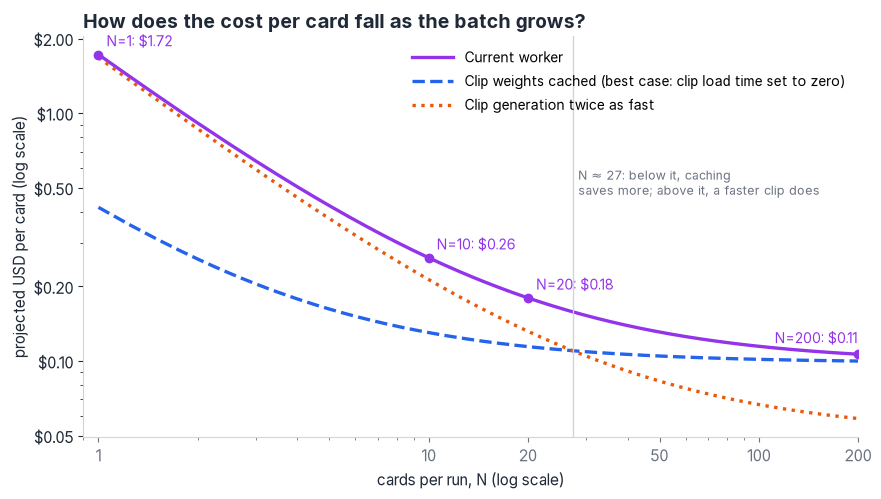

In [70]:
fig = costs.cost_vs_n_chart(steps, T_START_S, rate)
plt.show()

### 4.2 Parallel workers

Every worker pays `F` again: you buy wall time with money. 200 cards, split evenly across K workers that run fully in parallel:

In [71]:
N = 200
t_fixed_cached = T_START_S + t_load - clip["load_s"]  # best case: clip weights already on disk
for k in (1, 4, 10):
    wall_h = (t_fixed + N * t_gen / k) / 3600
    usd = rate / 3600 * (k * t_fixed + N * t_gen)
    usd_cached = rate / 3600 * (k * t_fixed_cached + N * t_gen)
    print(
        f"K={k:<3} wall time {wall_h:4.1f} h, cost ${usd:.2f} (${usd_cached:.2f} with cached clip weights)"
    )

K=1   wall time  4.7 h, cost $21.31 ($20.00 with cached clip weights)
K=4   wall time  1.5 h, cost $26.19 ($20.96 with cached clip weights)
K=10  wall time  0.8 h, cost $35.94 ($22.87 with cached clip weights)


### 4.3 Same cards, different GPUs

The same worker image and the same 20 kids, run once on each GPU. Cost per asset is price × time: a slower GPU can make a cheaper card. A run without all six steps is skipped.

`gpu_costs()` returns the numbers for one GPU at one price; section 5 reuses it for spot prices.

In [72]:
def gpu_costs(gpu: str, pricing: str) -> dict | None:
    """Card costs for one GPU's run at 'regular' or 'spot' prices; None if a step is missing."""
    s = load_run(gpu)["steps"]
    if set(s) != costs.ALL_STEPS:
        return None
    usd_h = PRICES[gpu][pricing]
    card = costs.card_cost(s, T_START_S, usd_h, counts=(20, 200))
    card_s = statistics.median(costs.card_times(s))
    return {
        "usd_h": usd_h,
        "clip_load_s": s["clip"]["load_s"],
        "card_s": card_s,
        "c": card["marginal_compute_usd"],
        "n20": card["projected_compute_usd_per_asset"]["20"],
        "n200": card["projected_compute_usd_per_asset"]["200"],
        "santa": (T_START_S + costs.model_loads(s) + 200_000 * card_s) * usd_h / 3600,
    }


print(f"regular prices, {PRICE_DATE}")
print(f"{'GPU':<14}{'USD/h':>7}{'clip load s':>13}{'card s':>8}{'c':>9}{'N=20':>9}{'N=200':>9}")
for gpu in PRICES:
    r = gpu_costs(gpu, "regular")
    if r is None:
        print(f"{gpu:<14}not all six steps, skipped")
        continue
    print(
        f"{gpu:<14}{r['usd_h']:>7.2f}{r['clip_load_s']:>13.0f}{r['card_s']:>8.1f}"
        f"{r['c']:>9.4f}{r['n20']:>9.4f}{r['n200']:>9.4f}"
    )

regular prices, 2026-11-15
GPU             USD/h  clip load s  card s        c     N=20    N=200
H100             4.50         1046    78.7   0.0984   0.1797   0.1065
H200             5.40          534    76.5   0.1148   0.1710   0.1204
RTX PRO 6000     1.80          531   125.6   0.0628   0.0814   0.0647


## 5. What spot prices change

Preemptible GPUs bill at the spot price. It's usually below the regular price, but how far below differs by GPU and region, and it moves during the day. It isn't capped: it can rise above the regular price unless you set a max price in a pricing policy. Nebius can also take a preemptible GPU back: the Job ends in `ERROR`, and a rerun pays the fixed part again.

The same numbers as section 4.3, at the spot snapshot in "Prices and assumptions". These are projections at that snapshot, not what the runs paid:

In [73]:
print(f"spot snapshot {SPOT_SNAPSHOT} vs regular, {PRICE_DATE}")
print(
    f"{'GPU':<14}{'regular':>9}{'spot':>7}{'saving':>8}{'c reg':>9}{'c spot':>9}"
    f"{'N=20 reg':>10}{'N=20 spot':>11}{'200k reg':>10}{'200k spot':>11}"
)
spot_rows = []
for gpu in PRICES:
    reg, spt = gpu_costs(gpu, "regular"), gpu_costs(gpu, "spot")
    if reg is None:
        continue
    spot_rows.append((gpu, reg["c"], spt["c"]))
    saving = 1 - spt["usd_h"] / reg["usd_h"]
    print(
        f"{gpu:<14}{reg['usd_h']:>9.2f}{spt['usd_h']:>7.2f}{saving:>8.0%}"
        f"{reg['c']:>9.4f}{spt['c']:>9.4f}{reg['n20']:>10.4f}{spt['n20']:>11.4f}"
        f"{reg['santa']:>10,.0f}{spt['santa']:>11,.0f}"
    )

cheapest = {
    pricing: min(
        (g for g in PRICES if gpu_costs(g, pricing)), key=lambda g: gpu_costs(g, pricing)["c"]
    )
    for pricing in ("regular", "spot")
}
print(
    f"\nlowest marginal cost per card: {cheapest['regular']} at regular prices, "
    f"{cheapest['spot']} at spot prices"
)

spot snapshot 2026-11-14T15:05Z vs regular, 2026-11-15
GPU             regular   spot  saving    c reg   c spot  N=20 reg  N=20 spot  200k reg  200k spot
H100               4.50   2.07     54%   0.0984   0.0453    0.1797     0.0827    19,683      9,054
H200               5.40   2.48     54%   0.1148   0.0527    0.1710     0.0785    22,959     10,544
RTX PRO 6000       1.80   1.38     23%   0.0628   0.0482    0.0814     0.0624    12,563      9,631

lowest marginal cost per card: RTX PRO 6000 at regular prices, H100 at spot prices


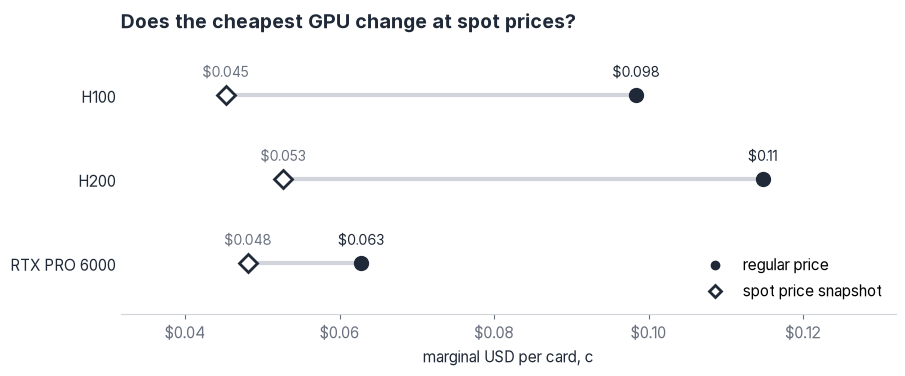

In [74]:
fig = costs.spot_chart(spot_rows)
plt.show()

## 6. Self-hosted vs the API: the clip step

The clip is most of the card's cost, so we compare that step, and only that step: the API sells the same model, Wan 2.2 A14B image-to-video. `F` is the startup plus the clip model's load, and `c` is the median clip time. A one-step run has the same shape as any single-model run: one model, one load, N assets.

The API prices per **video second** by resolution, counted at 16 frames per second. Our clip is 480p and 81 frames. The price is the one in "Prices and assumptions", checked on the date there; the provider can change it at any time.

In [75]:
p = costs.api_price_per_clip(API, WAN_I2V.num_frames)
print(
    f"API: {API['provider']} {API['model']}, {API['resolution']}, "
    f"${API['usd_per_video_s']} per video s x {WAN_I2V.num_frames / API['frames_per_video_s']:.2f} s "
    f"= ${p:.4f} per clip (checked {API['checked']}, {API['link']})"
)

for pricing in ("regular", "spot"):
    clip_cost = costs.clip_cost(steps, T_START_S, PRICES[MAIN_GPU][pricing], p)
    print(
        f"\nself-hosted clip on {MAIN_GPU}, {pricing} price: "
        f"c = ${clip_cost['marginal_compute_usd']:.4f}, F = ${clip_cost['fixed_run_usd']:.2f}"
    )
    for n, usd in clip_cost["projected_compute_usd_per_asset"].items():
        print(f"  N={n:<4} ${usd:.4f} per clip vs API ${p:.4f}")
    print(f"  breakeven: {clip_cost['breakeven_assets'] or 'never (0)'} clips per run")

API: fal fal-ai/wan/v2.2-a14b/image-to-video, 480p, $0.04 per video s x 5.06 s = $0.2025 per clip (checked 2026-11-15, https://fal.ai/models/fal-ai/wan/v2.2-a14b/image-to-video)

self-hosted clip on H100, regular price: c = $0.0958, F = $1.50
  N=1    $1.6004 per clip vs API $0.2025
  N=10   $0.2463 per clip vs API $0.2025
  N=20   $0.1711 per clip vs API $0.2025
  N=200  $0.1034 per clip vs API $0.2025
  breakeven: 15 clips per run

self-hosted clip on H100, spot price: c = $0.0441, F = $0.69
  N=1    $0.7362 per clip vs API $0.2025
  N=10   $0.1133 per clip vs API $0.2025
  N=20   $0.0787 per clip vs API $0.2025
  N=200  $0.0475 per clip vs API $0.2025
  breakeven: 5 clips per run


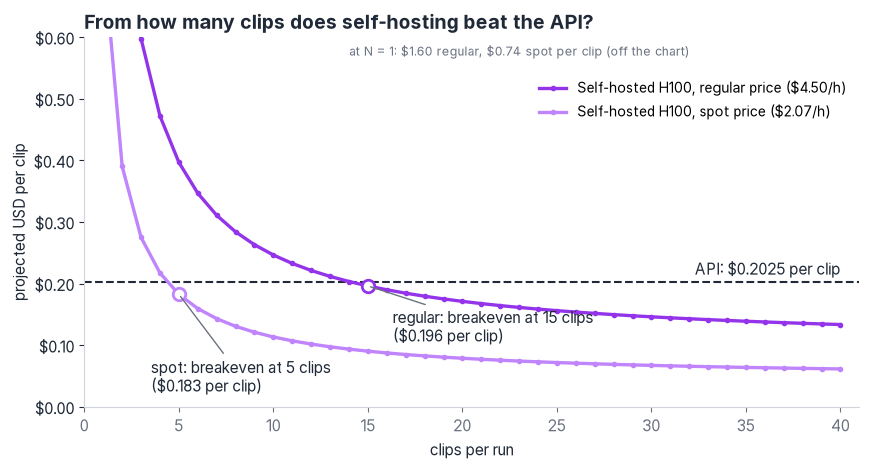

In [76]:
rates = {pricing: PRICES[MAIN_GPU][pricing] for pricing in ("regular", "spot")}
fig = costs.breakeven_chart(steps["clip"], T_START_S, rates, p, gpu=MAIN_GPU)
plt.show()

The breakeven also depends on the GPU. Every run with a clip step, at both prices:

In [77]:
print(f"{'GPU':<14}{'median clip s':>15}{'regular':>9}{'spot':>6}")
for gpu in PRICES:
    run_steps = load_run(gpu)["steps"]
    if "clip" not in run_steps:
        continue
    reg, spt = (
        costs.clip_cost(run_steps, T_START_S, PRICES[gpu][pricing], p)["breakeven_assets"]
        for pricing in ("regular", "spot")
    )
    print(f"{gpu:<14}{run_steps['clip']['median_s']:>15.1f}{reg or 'never':>9}{spt or 'never':>6}")

GPU             median clip s  regular  spot
H100                     76.7       15     5
H200                     74.6       12     4
RTX PRO 6000            123.6        3     2


## 7. Your lesson 04 run (practice)

Your lesson 04 Job wrote `metrics_batch.json` next to the cards in your bucket. If it's still there, download it.


Set `MY_METRICS` to its path and run the next cell. It splits your run the same way as sections 2 to 4, then projects the cost per card at N = 1, at your run's N and at N = 1000, and the clip breakeven against fal.

Two things aren't in the file:

- **The startup.** `MY_T_START` defaults to our 157.7 s. Yours is `created_at` → `started_at` in `nebius ai job get <job_ID> --format json`.
- **The price.** `MY_RATE` defaults to the section 0 price for the platform in your file: spot for a preemptible run, regular otherwise. Set it to the rate your run paid if you know it.

In [78]:
# TODO: Replace with your own metrics_batch.json path
MY_METRICS = Path("../assets/example_runs/h100.json")  # path to your lesson 04 metrics_batch.json
MY_T_START = None  # s, Create -> container running; None uses our T_START_S
MY_RATE = 1.5  # USD per hour your run paid; None uses section 0's price for the file's platform

# Run cell to calculate the cost per card for your run
mine = costs.read_run(MY_METRICS)
my_steps = mine["steps"]
my_start = T_START_S if MY_T_START is None else MY_T_START
if MY_RATE is None:
    my_rate, rate_from = costs.rate_for(mine, PRICES)  # section 0's price for the file's platform
else:
    my_rate, rate_from = MY_RATE, "MY_RATE"

print(
    f"{mine['n']} cards on {mine['gpu']}, {mine.get('region', '?')}, "
    f"billing {mine.get('billing', '?')}, steps: {', '.join(my_steps)}"
)
costs.print_steps(my_steps)
print(
    f"\nstartup {my_start:.1f} s ({'our measurement' if MY_T_START is None else 'yours'}), "
    f"model loads {costs.model_loads(my_steps):.1f} s, "
    f"median per card {statistics.median(costs.card_times(my_steps)):.1f} s"
)

my_cost = costs.card_cost(my_steps, my_start, my_rate, counts=(1, mine["n"], 1000))
print(
    f"rate {my_rate:.2f} USD/h from {rate_from}: "
    f"F = ${my_cost['fixed_run_usd']:.2f}, c = ${my_cost['marginal_compute_usd']:.4f}"
)
for n, usd in my_cost["projected_compute_usd_per_asset"].items():
    print(f"  N={n:<5} ${usd:.4f} per card, ${usd * int(n):,.2f} for the run")

20 cards on NVIDIA H100 80GB HBM3, eu-north1, billing preemptible, steps: text, illustration, card, clip, greeting, mix
step         runs on     load s  first s  median s  % of card
text         CPU              -      0.0       0.0       0.0%
illustration GPU           89.9      6.0       0.8       1.0%
card         CPU              -      0.4       0.4       0.5%
clip         GPU         1046.0     77.7      76.7      97.4%
greeting     GPU            7.3      2.2       0.2       0.2%
mix          CPU              -      0.6       0.6       0.7%

startup 157.7 s (our measurement), model loads 1143.2 s, median per card 78.7 s
rate 1.50 USD/h from MY_RATE: F = $0.54, c = $0.0328
  N=1     $0.5748 per card, $0.57 for the run
  N=20    $0.0599 per card, $1.20 for the run
  N=1000  $0.0333 per card, $33.34 for the run


> ⚠️ **Remove all running resources after the lesson to prevent bills.** Stop or delete every Endpoint, Job and DevLab you started, even after a failed run, and delete bucket data you no longer need. An Endpoint or DevLab keeps billing while it runs, even when idle.